# 04 — Optimization log (runs 006–012)

**Question.** Starting from the best model after the baselines (`004_linear_qr`), which single, pre-declared
changes from the fixed search space (spec §7) improve the probabilistic forecast on the validation folds — and
when should we stop searching?

**Protocol (fixed before run 006).**

- Budget: at most 15 more runs (006–020); stop early after 5 consecutive rejections, or when further runs would
  only be fitting validation noise.
- Each run is a YAML config whose falsifiable hypothesis was written *before* the run, and changes exactly one
  thing relative to the current best. The one declared exception: run 006 is `005_lgbm` + CQR (relative to 005,
  not 004), because 005 was the strongest sharp model and failed only on coverage.
- Search space: candidate features (`windfc.features.CANDIDATE_FEATURES`), LightGBM `num_leaves` 8–64,
  `learning_rate` 0.02–0.1, `n_estimators` 100–1500, `min_child_samples` 20–200, `feature_fraction` 0.6–1.0;
  recency half-life 90–730 days or none; CQR calibration window 30–180 days or none; LightGBM vs linear QR.
- Acceptance (`windfc.run.decide`, frozen): mean CRPS ≤ 0.99 × current best, CRPS better on ≥ 3 of 4 folds,
  P50 MAE ≤ 1.01 × best, mean P10–P90 coverage in [0.76, 0.84].
- Evaluation code frozen at commit `1b685ed`; each config was committed together with its log row
  (`exp: run <id> — <decision>`). The locked test period (delivery days ≥ 2026-05-01) is not loaded here.

"CRPS" below is the frozen metric: the pinball loss averaged over the nine quantiles τ = 0.1 … 0.9, in MWh per
hour, averaged over the four validation folds (8,580 scored hours).

**Outcome in one line.** Two changes were accepted (006: LightGBM + CQR; 007: 365-day recency weighting); the next
five were rejected, which triggered the stop rule after 7 of the 15 allowed runs.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from windfc import QUANTILES
from windfc.evaluate import QCOLS, TEST_PERIOD, diebold_mariano, pinball
from windfc.notebook import fold_table, rerun
from windfc.run import REPO_ROOT as ROOT, read_log

TEST_START = pd.Timestamp(TEST_PERIOD[0])
FIG_DIR = ROOT / "docs" / "figures"
LOG = ROOT / "experiments" / "log.csv"
CONFIGS = ROOT / "experiments" / "configs"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 200)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "lines.linewidth": 1.6, "legend.frameon": False,
})
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "ink": "#0b0b0b", "grey": "#8a8984"}

log = read_log(LOG)  # read only; rerun() writes to a temp log and refuses this path
print(f"{len(log)} logged runs; frozen eval header: {LOG.read_text().splitlines()[0]}")

12 logged runs; frozen eval header: # frozen_eval_commit=1b685ed11d837eab6f257ee4021c7ed50aecfde7


## 1. The full run log

Every row of `experiments/log.csv`, baselines and rejections included, unedited.

In [2]:
cols = ["run_id", "model", "crps_f1", "crps_f2", "crps_f3", "crps_f4", "crps_mean", "mae_p50_mean",
        "coverage_mean", "bias_mean", "n_hours", "decision", "reason"]
log[cols].set_index("run_id").round(3)

,model,crps_f1,crps_f2,crps_f3,crps_f4,crps_mean,mae_p50_mean,coverage_mean,bias_mean,n_hours,decision,reason
run_id,,,,,,,,,,,,
001_persistence,persistence,347.252,366.117,513.364,424.288,412.755,1068.248,0.792,-28.319,8580,baseline,baseline model; not eligible as current best
002_vendor_raw,vendor_raw,122.905,122.281,130.880,100.825,119.223,299.586,0.773,-4.294,8580,baseline,baseline model; not eligible as current best
003_vendor_capacity,vendor_capacity,124.344,123.041,132.508,103.050,120.736,303.013,0.778,15.298,8580,baseline,baseline model; not eligible as current best
004_linear_qr,linear_qr,112.467,121.799,123.813,108.470,116.637,296.271,0.778,-38.027,8580,accepted,initial best
005_lgbm,lgbm,109.745,121.160,104.393,99.409,108.677,274.076,0.693,-25.604,8580,rejected,"coverage_mean 0.693 outside [0.76, 0.84]"
006_lgbm_cqr90,lgbm,110.090,122.630,104.044,100.382,109.286,277.608,0.798,-29.348,8580,accepted,"crps_mean 109.3 vs 116.6 (6.30% gain), 3/4 folds"
007_hl365,lgbm,107.321,121.219,103.521,95.697,106.940,272.316,0.795,-32.124,8580,accepted,"crps_mean 106.9 vs 109.3 (2.15% gain), 4/4 folds"
008_err_mean_30d,lgbm,108.585,122.842,101.831,95.543,107.200,273.450,0.795,-14.655,8580,rejected,crps_mean 107.2 > 0.99 x best 106.9 (gain -0.24% < 1%); crps improves on only 2/4 folds (< 3)
009_min_child_100,lgbm,106.552,121.320,102.394,94.980,106.311,271.942,0.790,-24.728,8580,rejected,crps_mean 106.3 > 0.99 x best 106.9 (gain 0.59% < 1%)


In [3]:
# Hypothesis and change exactly as logged (written into the config before each run).
log[["run_id", "hypothesis", "change"]].set_index("run_id")

,hypothesis,change
run_id,,
001_persistence,"Carrying the last known actual forward 15-38 h sets a skill floor that any useful forecast, including the raw vendor, must beat by a wide margin.",baseline: persistence of last known actual (D-1 09:00 UTC) + 90-day empirical residual quantiles
002_vendor_raw,"The raw vendor day-ahead total, with level-binned 90-day empirical error quantiles, beats persistence by a wide margin but carries a large negative bias from uncovered offshore capacity.",baseline: vendor DA total (da_total) + 90-day empirical error quantiles in 5 forecast-level bins
003_vendor_capacity,Scaling the vendor offshore DA by the trailing 30-day actual/current offshore ratio removes most of the negative bias and lowers CRPS versus the raw vendor on most folds.,"baseline: capacity-corrected vendor DA total (da_total_adj, step 1) + 90-day empirical error quantiles in 5 forecast-level bins"
004_linear_qr,"Linear quantile regression on the capacity-corrected vendor features, ramps, calendar and trailing error stats improves CRPS over the empirical vendor baseline by learning level-dependent spread a...","linear quantile regression (alpha 0, default stride subsample) on BASE_FEATURES"
005_lgbm,"LightGBM quantile regression with default parameters on the same base features captures non-linear power-curve and error-regime effects and beats linear QR on CRPS, possibly at the cost of under-c...","LightGBM quantile regression, one model per quantile, LightGBM default parameters, on BASE_FEATURES"
006_lgbm_cqr90,Wrapping 005's LightGBM in CQR with a 90-day calibration window widens its under-covered intervals (0.69) into the 0.76-0.84 band while keeping mean CRPS at least 1% below 004_linear_qr on at leas...,"005_lgbm + CQR (cqr_calib_days 90); relative to 005, not to the current best 004, because 005 is the strongest sharp model and its only failure was coverage (permitted first-lgbm exception)"
007_hl365,"Exponential recency weighting with a 365-day half-life makes the 006 LightGBM+CQR model track the current fleet and error regime, shrinking its negative bias (fold 3 bias -90 MW) and lowering mean...","006_lgbm_cqr90 with half_life_days 365 (was null, full-history equal weights)"
008_err_mean_30d,"Adding the 30-day mean vendor error gives the model a less noisy estimate of the persistent vendor bias than the 7-day mean alone, reducing the large fold-3 under-forecast (bias -104 MW) and lower...",007_hl365 + feature err_mean_30d
009_min_child_100,"005's raw LightGBM intervals covered only 0.69 out of sample, a sign that default 20-row leaves overfit the tail quantiles; raising min_child_samples to 100 regularizes the leaves and lowers 007's...",007_hl365 with LightGBM min_child_samples 100 (default 20)


## 2. Hypothesis → result → decision

For each loop run: why it was chosen (from the evidence available at the time), the CRPS change against the
current best *at that moment*, how many folds improved, and the decision. The "why" notes were written during
the loop; the diagnostics they cite are reproduced in section 5.

In [4]:
why = {
    "006_lgbm_cqr90": "005 was the sharpest model (CRPS 108.7) and failed only on coverage (0.69); CQR is the "
                      "search-space tool aimed exactly at that failure. 90 days = middle of the allowed window.",
    "007_hl365": "006 still had a large negative P50 bias in fold 3 (-90 MWh) and the fleet and vendor change over "
                 "the 3+ years of training history; recency weighting is the direct lever for non-stationarity.",
    "008_err_mean_30d": "Fold-3 bias was still -104 MWh after 007; a 30-day error mean is a steadier estimate of "
                        "persistent vendor bias than the 7-day one.",
    "009_min_child_100": "005's raw intervals were far too narrow out of sample (0.69 coverage): a classic sign of "
                         "over-fitted quantile leaves; larger leaves regularise the tails.",
    "010_cqr30": "With recency weighting, the 90-day CQR hold-out removes the highest-weight days from fitting; "
                 "a 30-day hold-out returns 60 of them.",
    "011_hl180": "365-day half-life improved all 4 folds over equal weights; testing whether the drift is faster "
                 "still.",
    "012_err_by_hour_30d": "007's P50 residuals showed a diurnal pattern (over-forecast 08-15 UTC, under-forecast "
                           "at night, about +/-60 MWh) not removed by the static hour feature.",
}
loop = log[log.run_id.isin(why)].reset_index(drop=True)
rows, best = [], log[log.run_id == "004_linear_qr"].iloc[0]
for _, r in loop.iterrows():
    folds_better = sum(r[f"crps_f{i}"] < best[f"crps_f{i}"] for i in range(1, 5))
    rows.append(dict(run_id=r.run_id, vs_best=best.run_id, why=why[r.run_id],
                     crps=r.crps_mean, d_crps_pct=100 * (r.crps_mean / best.crps_mean - 1),
                     folds_better=f"{folds_better}/4", coverage=r.coverage_mean,
                     d_mae_pct=100 * (r.mae_p50_mean / best.mae_p50_mean - 1), decision=r.decision))
    if r.decision == "accepted":
        best = r
hrd = pd.DataFrame(rows).set_index("run_id")
hrd.round(2)

,vs_best,why,crps,d_crps_pct,folds_better,coverage,d_mae_pct,decision
run_id,,,,,,,,
006_lgbm_cqr90,004_linear_qr,005 was the sharpest model (CRPS 108.7) and failed only on coverage (0.69); CQR is the search-space tool aimed exactly at that failure. 90 days = middle of the allowed window.,109.29,-6.30,3/4,0.80,-6.30,accepted
007_hl365,006_lgbm_cqr90,006 still had a large negative P50 bias in fold 3 (-90 MWh) and the fleet and vendor change over the 3+ years of training history; recency weighting is the direct lever for non-stationarity.,106.94,-2.15,4/4,0.80,-1.91,accepted
008_err_mean_30d,007_hl365,Fold-3 bias was still -104 MWh after 007; a 30-day error mean is a steadier estimate of persistent vendor bias than the 7-day one.,107.20,0.24,2/4,0.80,0.42,rejected
009_min_child_100,007_hl365,005's raw intervals were far too narrow out of sample (0.69 coverage): a classic sign of over-fitted quantile leaves; larger leaves regularise the tails.,106.31,-0.59,3/4,0.79,-0.14,rejected
010_cqr30,007_hl365,"With recency weighting, the 90-day CQR hold-out removes the highest-weight days from fitting; a 30-day hold-out returns 60 of them.",107.27,0.31,1/4,0.80,-0.39,rejected
011_hl180,007_hl365,365-day half-life improved all 4 folds over equal weights; testing whether the drift is faster still.,106.92,-0.02,3/4,0.78,0.38,rejected
012_err_by_hour_30d,007_hl365,"007's P50 residuals showed a diurnal pattern (over-forecast 08-15 UTC, under-forecast at night, about +/-60 MWh) not removed by the static hour feature.",105.86,-1.01,2/4,0.79,-0.73,rejected


**Reading.** The two accepted runs are also the two largest effects: −6.3% (006) and −2.2% (007, all four folds).
The five rejections fall into three groups:

- **Too small to clear 1%** — `009_min_child_100` (−0.6%, 3/4 folds) and `011_hl180` (−0.02%).
- **Trades folds against each other** — `008_err_mean_30d` (helps fold 3, hurts folds 1–2) and
  `012_err_by_hour_30d`, which clears the 1% mean threshold (−1.01%) but only by a large fold-1 gain (−5.7%)
  while folds 2 and 4 get worse. The 3-of-4-fold rule exists precisely to reject this pattern.
- **Hypothesis falsified** — `010_cqr30`: shorter calibration made coverage unstable (per-fold 0.71–0.91), with no
  CRPS gain. Its *mean* coverage (0.796) passes the guardrail, which shows the guardrail only checks the average.

## 3. CRPS of the current best over run number

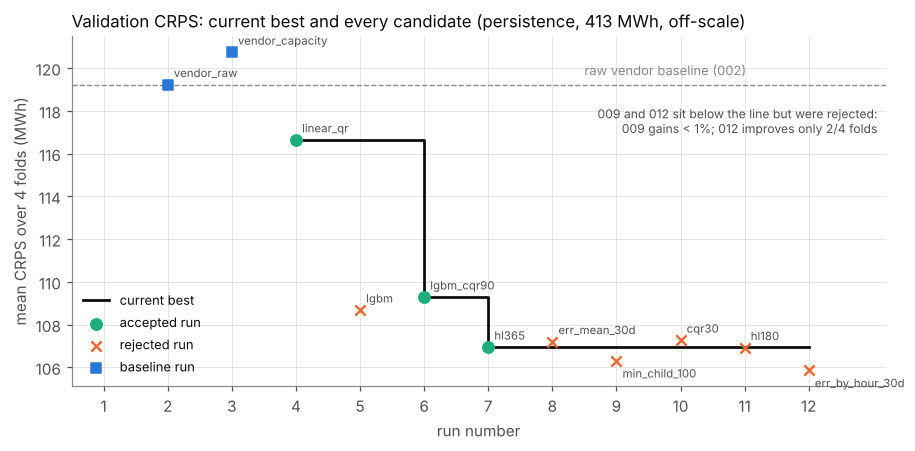

,crps_mean,decision,best_so_far
run_id,,,
001_persistence,412.76,baseline,NaN
002_vendor_raw,119.22,baseline,NaN
003_vendor_capacity,120.74,baseline,NaN
004_linear_qr,116.64,accepted,116.64
005_lgbm,108.68,rejected,116.64
006_lgbm_cqr90,109.29,accepted,109.29
007_hl365,106.94,accepted,106.94
008_err_mean_30d,107.20,rejected,106.94
009_min_child_100,106.31,rejected,106.94


In [5]:
d = log.reset_index(drop=True)
d["run_no"] = d.run_id.str[:3].astype(int)
cur, traj = np.nan, []
for _, r in d.iterrows():
    if r.decision == "accepted":
        cur = r.crps_mean
    traj.append(cur)
d["best_so_far"] = traj
ref = float(d.loc[d.run_id == "002_vendor_raw", "crps_mean"].iloc[0])

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.axhline(ref, color=C["grey"], lw=0.9, ls="--")
ax.text(8.5, ref + 0.3, "raw vendor baseline (002)", va="bottom", fontsize=8.5, color=C["grey"])
m = d.best_so_far.notna()
ax.step(d.run_no[m], d.best_so_far[m], where="post", color=C["ink"], lw=1.8, label="current best")
style = {"accepted": dict(color=C["aqua"], marker="o", s=55),
         "rejected": dict(color=C["orange"], marker="x", s=45),
         "baseline": dict(color=C["blue"], marker="s", s=35)}
show = d[d.run_id != "001_persistence"]  # persistence (CRPS 413) is off-scale
for dec, st in style.items():
    s = show[show.decision == dec]
    ax.scatter(s.run_no, s.crps_mean, label=f"{dec} run", zorder=3, **st)
for _, r in show.iterrows():
    ax.annotate(r.run_id[4:], (r.run_no, r.crps_mean), xytext=(4, -11 if r.run_no in (9, 12) else 5), textcoords="offset points",
                fontsize=7.5, color="#52514e")
ax.set_xticks(d.run_no)
ax.set_xlim(0.5, 13.2)
ax.set_xlabel("run number")
ax.set_ylabel("mean CRPS over 4 folds (MWh)")
ax.set_title("Validation CRPS: current best and every candidate (persistence, 413 MWh, off-scale)",
             loc="left", fontsize=11)
ax.text(0.99, 0.80, "009 and 012 sit below the line but were rejected:\n009 gains < 1%; 012 improves only 2/4 folds",
        transform=ax.transAxes, ha="right", va="top", fontsize=8, color="#52514e")
ax.legend(loc="lower left", fontsize=8.5)
fig.tight_layout()
fig.savefig(FIG_DIR / "optimization_trajectory.png", bbox_inches="tight")
plt.show()
d[["run_id", "crps_mean", "decision", "best_so_far"]].set_index("run_id").round(2)

## 4. Reproduce the key runs and test the differences

Re-run the configs into throwaway logs (`windfc.notebook.rerun` asserts that each reproduces its logged mean
CRPS), then compare per-hour losses with the frozen Diebold–Mariano test (HLN-corrected, on delivery-day mean
losses, pooled over the 4 folds, ≈ 360 days). A negative statistic means the first run is better.

In [6]:
ids = ["002_vendor_raw", "004_linear_qr", "006_lgbm_cqr90", "007_hl365", "008_err_mean_30d",
       "009_min_child_100", "010_cqr30", "011_hl180", "012_err_by_hour_30d"]
res = {rid: rerun(CONFIGS / f"{rid}.yaml") for rid in ids}
for r in res.values():  # validation hours only
    assert (r["predictions"].index < TEST_START).all()
loss = {rid: pinball(r["predictions"]["actual_total"], r["predictions"]) for rid, r in res.items()}

pairs = [("006_lgbm_cqr90", "004_linear_qr"), ("007_hl365", "006_lgbm_cqr90"),
         ("007_hl365", "004_linear_qr"), ("007_hl365", "002_vendor_raw"),
         ("008_err_mean_30d", "007_hl365"), ("009_min_child_100", "007_hl365"),
         ("010_cqr30", "007_hl365"), ("011_hl180", "007_hl365"), ("012_err_by_hour_30d", "007_hl365")]
dm = []
for a, b in pairs:
    stat, p = diebold_mariano(loss[a], loss[b])
    dm.append(dict(run=a, vs=b, d_crps=loss[a].mean() - loss[b].mean(),
                   d_crps_pct=100 * (loss[a].mean() / loss[b].mean() - 1), dm_stat=stat, p_value=p,
                   decision=log.set_index("run_id").loc[a, "decision"]))
pd.DataFrame(dm).set_index(["run", "vs"]).round(4)

d_crps  d_crps_pct  dm_stat    p_value  decision
run                 vs                                                              
006_lgbm_cqr90      004_linear_qr   -7.270      -6.237   -5.763  0.000e+00  accepted
007_hl365           006_lgbm_cqr90  -2.357      -2.156   -3.471  6.000e-04  accepted
                    004_linear_qr   -9.627      -8.259   -7.175  0.000e+00  accepted
                    002_vendor_raw -12.265     -10.289   -6.399  0.000e+00  accepted
008_err_mean_30d    007_hl365        0.275       0.257    0.564  5.734e-01  rejected
009_min_child_100   007_hl365       -0.628      -0.587   -2.178  3.010e-02  rejected
010_cqr30           007_hl365        0.324       0.303    0.766  4.443e-01  rejected
011_hl180           007_hl365       -0.020      -0.019   -0.056  9.554e-01  rejected
012_err_by_hour_30d 007_hl365       -1.117      -1.044   -1.535  1.257e-01  rejected

**Reading.**

- Both accepted steps are clearly distinguishable from noise on this test (006 vs 004: DM ≈ −5.8; 007 vs 006:
  DM ≈ −3.5, p < 0.001), and the final best beats the raw vendor baseline with DM ≈ −6.4.
- `009_min_child_100` is *also* significant at the 5% level (p ≈ 0.03) despite being rejected: its gain is real but
  only 0.6%, below the 1% materiality threshold that was fixed in advance. I did not relax the rule after seeing
  this; the rule is deliberately conservative.
- `012_err_by_hour_30d` has the largest mean gain of the rejections (−1.0%) but is not significant (p ≈ 0.13)
  and wins on only 2 folds — consistent with a gain concentrated in one season.
- Caveat: these p-values are not corrected for the ~10 comparisons, and the hypotheses were chosen adaptively on
  the same folds, so they overstate confidence.

## 5. The final best (`007_hl365`) fold by fold

In [7]:
ft = fold_table([res[k] for k in ["002_vendor_raw", "004_linear_qr", "006_lgbm_cqr90", "007_hl365"]])
wide = {k: ft.pivot(index="fold", columns="run", values=k) for k in ["crps", "mae_p50", "coverage_80", "bias"]}
pd.concat(wide, axis=1).round(2)

crps                                               mae_p50                                           coverage_80                               \
run  002_vendor_raw 004_linear_qr 006_lgbm_cqr90 007_hl365 002_vendor_raw 004_linear_qr 006_lgbm_cqr90 007_hl365 002_vendor_raw 004_linear_qr 006_lgbm_cqr90   
fold                                                                                                                                                           
1            122.91        112.47         110.09    107.32         309.97        286.11         280.26    274.45           0.77          0.75           0.75   
2            122.28        121.80         122.63    121.22         312.85        309.71         308.78    304.27           0.80          0.77           0.78   
3            130.88        123.81         104.04    103.52         323.20        317.85         268.37    267.09           0.73          0.76           0.82   
4            100.82        108.47         100.38     95.70         252.32        271.41         253.03    243.46           0.80          0.84           0.84   

                         bias                                         
run  007_hl365 002_vendor_raw 004_linear_qr 006_lgbm_cqr90 007_hl365  
fold                                                                  
1         0.75         146.59         10.26         -22.39    -23.55  
2         0.76          -4.07          5.12          11.25      2.78  
3         0.83        -173.63       -135.40         -90.33   -104.01  
4         0.84          13.94        -32.10         -15.92     -3.71

In [8]:
# Diagnostics cited in the 'why' notes: residual (P50 - actual) by forecast level and by hour, and
# P10-P90 coverage by forecast-level quintile, for the final best.
p = res["007_hl365"]["predictions"].copy()
p["res"] = p.q50 - p.actual_total
p["level_quintile"] = pd.qcut(p.q50, 5, labels=[f"Q{i}" for i in range(1, 6)])
p["inside"] = (p.actual_total >= p.q10) & (p.actual_total <= p.q90)
p["hour_block"] = (p.index.hour // 4 * 4).map(lambda h: f"{h:02d}-{h + 3:02d} UTC")
by_level = pd.concat({"mean P50 residual (MWh)": p.pivot_table(index="level_quintile", columns="fold",
                                                                values="res", aggfunc="mean", observed=True),
                      "P10-P90 coverage": p.pivot_table(index="level_quintile", columns="fold",
                                                        values="inside", observed=True)}, axis=1)
display(by_level.round(2))
p.groupby("hour_block").res.agg(mean_residual="mean", mae=lambda s: s.abs().mean()).round(1)

mean P50 residual (MWh)                        P10-P90 coverage                  
fold                                 1       2       3      4                1     2     3     4
level_quintile                                                                                  
Q1                              -20.30  -59.67  -25.80 -25.75             0.92  0.87  0.95  0.91
Q2                              -25.29  -64.75  -24.97  51.49             0.77  0.85  0.88  0.87
Q3                              -10.01  -71.45 -103.36  67.26             0.71  0.84  0.78  0.87
Q4                              -23.00   80.62  -96.15  24.44             0.63  0.66  0.74  0.83
Q5                             -108.98  172.18 -184.15 -70.26             0.64  0.51  0.84  0.76

,mean_residual,mae
hour_block,,
00-03 UTC,-57.8,230.2
04-07 UTC,-68.8,254.3
08-11 UTC,49.3,289.7
12-15 UTC,28.4,331.6
16-19 UTC,-81.1,269.1
20-23 UTC,-61.1,258.8


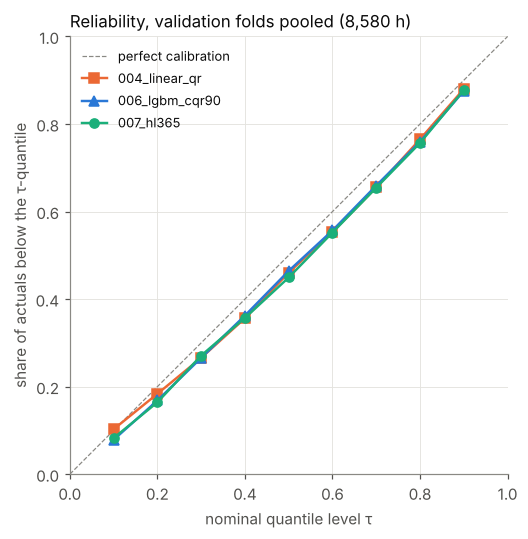

,004_linear_qr,006_lgbm_cqr90,007_hl365
nominal τ,,,
0.1,0.103,0.079,0.083
0.2,0.184,0.168,0.164
0.3,0.266,0.266,0.271
0.4,0.356,0.362,0.357
0.5,0.460,0.464,0.449
0.6,0.553,0.557,0.552
0.7,0.655,0.659,0.655
0.8,0.765,0.759,0.757
0.9,0.880,0.876,0.878


In [9]:
rel = pd.DataFrame({rid: [(res[rid]["predictions"]["actual_total"] <= res[rid]["predictions"][q]).mean()
                          for q in QCOLS] for rid in ["004_linear_qr", "006_lgbm_cqr90", "007_hl365"]},
                   index=pd.Index(QUANTILES, name="nominal τ"))
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], color=C["grey"], lw=0.8, ls="--", label="perfect calibration")
for (rid, colour), marker in zip({"004_linear_qr": C["orange"], "006_lgbm_cqr90": C["blue"],
                                   "007_hl365": C["aqua"]}.items(), ["s", "^", "o"]):
    ax.plot(rel.index, rel[rid], color=colour, marker=marker, ms=6, label=rid)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_xlabel("nominal quantile level τ")
ax.set_ylabel("share of actuals below the τ-quantile")
ax.set_title("Reliability, validation folds pooled (8,580 h)", loc="left", fontsize=11)
ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
plt.show()
rel.round(3)

**Reading.**

- The final best improves CRPS over the raw vendor on every fold, but the gain is very uneven: −21% in fold 3
  (Nov–Jan) and −13% in fold 1 (May–Jul), −5% in fold 4, and under −1% in fold 2 (Aug–Oct), where LightGBM has
  never beaten linear QR by much.
- Per-fold coverage of the final best is 0.751, 0.757, 0.831, 0.842: folds 1–2 are just below the 0.76 lower
  bound and folds 3–4 at the upper end. Only the 4-fold mean (0.795) is inside the band.
- Pooled reliability is within ≈ 5 points of the diagonal, with a downward shift (45% of actuals below the P50,
  i.e. a mild under-forecast), a lower tail slightly too wide (8.3% below P10) and an upper tail slightly too
  narrow (12.2% above P90). The pooled view also hides structure: coverage falls with forecast level
  (0.87–0.95 in the lowest-level quintile, 0.51–0.84 in the highest). The CQR wrapper adds one *constant* width per
  quantile pair, so it over-widens calm hours and under-widens windy hours. A level-scaled conformal score would
  address this, but it is a code change outside the §7 search space, so it was not attempted in this loop.
- A winter under-forecast remains (fold-3 P50 bias ≈ −104 MWh, concentrated in the upper level quintiles), and
  in fold 2 the highest-level hours are over-forecast instead (+172 MWh) — the high-output error changes sign by
  season. Neither of the
  two runs aimed at it (008, 012) fixed it without hurting other seasons.

## 6. The accepted changes in plain English

**006 — LightGBM + conformal calibration (CQR, 90-day window).** LightGBM learns how the vendor forecast's error
depends on the forecast level, ramps, time of day and recent vendor performance, which makes it sharper than the
linear model; on its own its 80% interval only contained 69% of outcomes. CQR fixes that empirically: it holds back
the last 90 days of training data, measures how often and by how much the model's intervals missed there, and
widens every interval by that amount. Result: coverage 0.69 → 0.80 at a small CRPS cost relative to raw LightGBM,
and 6.3% lower CRPS than the linear model.

**007 — Recency weighting with a 365-day half-life.** Each training hour is weighted by 0.5^(age / 365 days), so
data from a year ago counts half and three years ago one-eighth. The wind fleet, the vendor's model and its
error patterns change over time; weighting recent history more lets the model follow the current regime instead
of averaging over all of 2022–2025. It improved all four folds (−2.2% CRPS, MAE −1.9%) with coverage unchanged.

## 7. Conclusion

In [10]:
L = log.set_index("run_id")
fb, base = L.loc["007_hl365"], L.loc["002_vendor_raw"]
pd.DataFrame({
    "002_vendor_raw": [base.crps_mean, base.mae_p50_mean, base.coverage_mean, base.bias_mean],
    "007_hl365 (final best)": [fb.crps_mean, fb.mae_p50_mean, fb.coverage_mean, fb.bias_mean],
    "relative change %": [100 * (fb.crps_mean / base.crps_mean - 1), 100 * (fb.mae_p50_mean / base.mae_p50_mean - 1),
                          np.nan, np.nan],
}, index=["CRPS (MWh)", "P50 MAE (MWh)", "P10-P90 coverage", "P50 bias (MWh)"]).round(3)

,002_vendor_raw,007_hl365 (final best),relative change %
CRPS (MWh),119.223,106.940,-10.303
P50 MAE (MWh),299.586,272.316,-9.103
P10-P90 coverage,0.773,0.795,NaN
P50 bias (MWh),-4.294,-32.124,NaN


**Stopping.** The loop stopped after run 012 because runs 008–012 were five consecutive rejections — the
pre-declared stop rule — using 7 of the 15 allowed runs. Independently of the rule, the evidence said the search
had reached the noise floor of this validation design: after 007, every candidate moved mean CRPS by between
−1.0% and +0.3%, and the only one to clear 1% did so through a single fold. Spending the remaining 8 runs on
one-parameter nudges (n_estimators, num_leaves, feature_fraction, more half-lives) would mostly have been a search
for a lucky fold split.

**Total gain (validation only).** The final best, `007_hl365` (LightGBM quantile regression on `BASE_FEATURES`,
LightGBM default hyper-parameters, 365-day recency half-life, CQR with a 90-day calibration window), scores mean
CRPS 106.9 MWh vs 119.2 for the raw vendor baseline `002_vendor_raw` (**−10.3%**), P50 MAE 272.3 vs 299.6 MWh
(**−9.1%**), and P10–P90 coverage 0.795 vs 0.773 (target 0.80). It beats the baseline on all four folds
(DM ≈ −6.4). Against the pre-loop best `004_linear_qr` (116.6) the loop delivered −8.3%, but most of that
(006, −6.3%) is the "unlock" of LightGBM sharpness that 005 had already shown in notebook 03 (108.7, rejected only
for coverage); 007 (−2.2%) is the only accepted *tuning* step. Two qualifications: the pooled P50 bias is larger
for the final best (−32 MWh) than for the raw vendor (−4 MWh, which nets a +147 MWh fold 1 against a −174 MWh
fold 3), and coverage of the final best is below 0.76 in folds 1 and 2 (0.751, 0.757).

**What didn't work.** Longer error-window features (`err_mean_30d`, 008) and hour-of-day error features
(`err_by_hour_30d`, 012) each helped some seasons and hurt others; a faster recency decay (180 days, 011) added
nothing; a shorter CQR window (30 days, 010) made per-fold coverage swing between 0.71 and 0.91; stronger leaf
regularisation (`min_child_samples` 100, 009) gave a real but immaterial 0.6%. The remaining systematic weaknesses —
level-dependent coverage and a winter under-forecast at high output — are not fixable by anything in the §7
search space.

**Overfitting risk.** All selection happened on the same four 3-month folds (≈ 8,600 hours, one year of
seasons), and the next hypothesis was chosen after looking at fold-level results. With 7 adaptive comparisons the
best-of-N result is biased downward: expect part of the 007-vs-006 gain to shrink out of sample, and treat any
gain below ~1% as indistinguishable from noise. The safeguards were a one-change-per-run rule, a pre-fixed 1% /
3-of-4-fold threshold that rejected even a statistically significant 0.6% gain, and a locked test period
(2026-05-01 – 2026-10-28) that has not been loaded in this loop. Two residual risks remain: the coverage guardrail
checks only the mean over folds (run 010 passed it with fold-level coverage of 0.71–0.91; the final best has
two folds just under 0.76), and four folds are too
few to tell a seasonal effect from luck. The test-period evaluation of `007_hl365` — run once, after this notebook
— is the honest measure of what the loop achieved.